# Лабораторна робота №9
**Тема:** Класифікація зображень за допомогою згорткових нейронних мереж (CNN)  
**Виконав:** студент групи ФІТ Halchenko Yan  
**Варіант:** 8 (Класи Food-101: beef_carpaccio, edamame, hot_and_sour_soup)  
**Мета:** Побудувати згорткову нейронну мережу (CNN) для 3 взаємовиключних класів Food-101, провести контрольований експеримент з регуляризацією (Dropout), оцінити модель на незалежній тестовій вибірці та виконати аналіз карт ознак і помилок класифікації.

In [1]:
import os
import json
import random
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# 1. Фіксація відтворюваності (SEED = 42)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
keras.utils.set_random_seed(SEED)

# 2. Ручний розрахунок згортки
X = np.array([[1, 2, 0], [0, 1, 3], [2, 2, 1]], dtype=np.float32)
K = np.array([[1, 0], [0, -1]], dtype=np.float32)

conv_manual = np.array([[0, -1], [-2, 0]], dtype=np.float32)
bias = 1
relu_out = np.maximum(0, conv_manual + bias)

print("--- Ручний розрахунок згортки ---")
print("Вхід X:\n", X)
print("Ядро K:\n", K)
print("Карта згортки (Valid, Stride=1, Bias=0):\n", conv_manual)
print("Після додавання Bias=1 та активації ReLU:\n", relu_out)

--- Ручний розрахунок згортки ---
Вхід X:
 [[1. 2. 0.]
 [0. 1. 3.]
 [2. 2. 1.]]
Ядро K:
 [[ 1.  0.]
 [ 0. -1.]]
Карта згортки (Valid, Stride=1, Bias=0):
 [[ 0. -1.]
 [-2.  0.]]
Після додавання Bias=1 та активації ReLU:
 [[1. 0.]
 [0. 1.]]


## Етап 2. Підготовка індивідуального набору даних (Варіант n = 8)
Згідно з формулою $i_1 = n-1, i_2 = n+29, i_3 = n+59$ для $n=8$, отримано індекси 7, 37, 67.  
Відповідні класи Food-101: **beef_carpaccio**, **edamame**, **hot_and_sour_soup**.  
Формуємо структуровані папки `data/food101_lab9/` (train, val, test) та генеруємо `manifest.json`.

In [2]:
from pathlib import Path
import json
import random
import shutil

# Основна папка
BASE_DIR = Path("D:/Datasets/food-101")

# Перевірка вкладеності (якщо в середині D:/Datasets/food-101 є ще одна папка food-101)
if (BASE_DIR / "food-101/meta/classes.txt").is_file():
    FOOD_ROOT = BASE_DIR / "food-101"
elif (BASE_DIR / "meta/classes.txt").is_file():
    FOOD_ROOT = BASE_DIR
else:
    meta_paths = list(BASE_DIR.glob("**/meta/classes.txt"))
    if meta_paths:
        FOOD_ROOT = meta_paths[0].parent.parent
    else:
        raise FileNotFoundError(f"Не знайдено папку meta/classes.txt у {BASE_DIR}")

print(f"Корінь датасету знайдено: {FOOD_ROOT.resolve()}")

n = 8
all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text(encoding="utf-8").splitlines())
indices = [n - 1, n + 29, n + 59]
CLASS_NAMES = [all_classes[i] for i in indices]

print(f"Обрані класи для варіанта n={n}: {CLASS_NAMES}")
print("Мітки моделі:", dict(enumerate(CLASS_NAMES)))

DATA_DEST = Path("data/food101_lab9")
for split in ["train", "val", "test"]:
    for cls in CLASS_NAMES:
        (DATA_DEST / split / cls).mkdir(parents=True, exist_ok=True)

train_meta = (FOOD_ROOT / "meta/train.txt").read_text(encoding="utf-8").splitlines()
test_meta = (FOOD_ROOT / "meta/test.txt").read_text(encoding="utf-8").splitlines()

manifest_data = {"seed": SEED, "classes": CLASS_NAMES, "splits": {"train": [], "val": [], "test": []}}

for cls in CLASS_NAMES:
    cls_train_files = [f + ".jpg" for f in train_meta if f.startswith(f"{cls}/")]
    random.Random(SEED).shuffle(cls_train_files)
    
    val_files = cls_train_files[:150]
    train_files = cls_train_files[150:750]
    test_files = [f + ".jpg" for f in test_meta if f.startswith(f"{cls}/")][:250]
    
    for src_rel, split_name in [(train_files, "train"), (val_files, "val"), (test_files, "test")]:
        for fname in src_rel:
            src_path = FOOD_ROOT / "images" / fname
            dst_path = DATA_DEST / split_name / fname
            if src_path.exists() and not dst_path.exists():
                shutil.copy(src_path, dst_path)
            manifest_data["splits"][split_name].append(dst_path.relative_to(DATA_DEST).as_posix())

with open("manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest_data, f, indent=4)

print("Маніфест поділу успішно збережено у manifest.json!")

Корінь датасету знайдено: D:\Datasets\food-101
Обрані класи для варіанта n=8: ['bibimbap', 'filet_mignon', 'omelette']
Мітки моделі: {0: 'bibimbap', 1: 'filet_mignon', 2: 'omelette'}
Маніфест поділу успішно збережено у manifest.json!


## Етап 3. Створення TF.Data батчів та інспекція даних
Завантажуємо батчі зображень розміром $128 \times 128 \times 3$ із використанням `image_dataset_from_directory`.  
Перевіряємо розмірності тензорів та діапазони пікселів.

In [3]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
DATA_ROOT = Path("data/food101_lab9")

def load_split(part, training=False):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / part,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=training,
        seed=SEED
    )

train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val", training=False).prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test", training=False).prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print(f"Тензор зображень батчу: {images.shape}")
print(f"Тензор міток батчу: {labels.shape}")
print(f"Мін/Макс значення пікселів: {float(tf.reduce_min(images))}, {float(tf.reduce_max(images))}")

Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
Тензор зображень батчу: (32, 128, 128, 3)
Тензор міток батчу: (32,)
Мін/Макс значення пікселів: 0.0, 255.0


## Етап 4. Архітектура базової згорткової нейромережі (Baseline CNN)
Створюємо згорткову мережу з трьома Conv-блоками (16, 32, 64 фільтри $3 \times 3$), шаром `GlobalAveragePooling2D` та вихідним шаром `Dense(3, activation='softmax')`.  
Загальна кількість параметрів моделі становить **23,779**.

In [4]:
def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128, 128, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    
    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2)(x)
        
    x = layers.GlobalAveragePooling2D()(x)
    
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
        
    outputs = layers.Dense(3, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return model

base_model = make_model(dropout=0.0)
base_model.summary()
assert base_model.count_params() == 23779, "Кількість параметрів має бути рівно 23,779!"
print("Перевірку параметрів базової моделі успішно пройдено!")

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)

Перевірку параметрів базової моделі успішно пройдено!


## Етап 5. Навчання та проведення контрольованого експерименту (Dropout 0.3)
Проводимо порівняльний експеримент:
1. **Base Model:** Навчання без Dropout.
2. **Changed Model (Hypothesis):** Додавання `Dropout(0.3)` після шару GAP для зменшення ефекту перенавчання.

--- Навчання базової моделі (Baseline) ---
Found 1800 files belonging to 3 classes.
Epoch 1/30


c:\Users\MAX\Data_Science_Labs\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


57/57 ━━━━━━━━━━━━━━━━━━━━ 11s 161ms/step - accuracy: 0.4172 - loss: 1.0654 - val_accuracy: 0.5644 - val_loss: 1.0127
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - accuracy: 0.5472 - loss: 0.9574 - val_accuracy: 0.5711 - val_loss: 0.9841
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.5550 - loss: 0.9324 - val_accuracy: 0.5978 - val_loss: 0.9788
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.5911 - loss: 0.8958 - val_accuracy: 0.5889 - val_loss: 0.9250
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.6333 - loss: 0.8470 - val_accuracy: 0.6489 - val_loss: 0.8947
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - accuracy: 0.6061 - loss: 0.8574 - val_accuracy: 0.5800 - val_loss: 0.8896
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 98ms/step - accuracy: 0.6461 - loss: 0.8174 - val_accuracy: 0.6200 - val_loss: 0.8602
Epoch 8/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 95ms/step - accuracy: 0.6539 - loss: 0.7972 - val_accuracy: 0.6200 - val_loss:

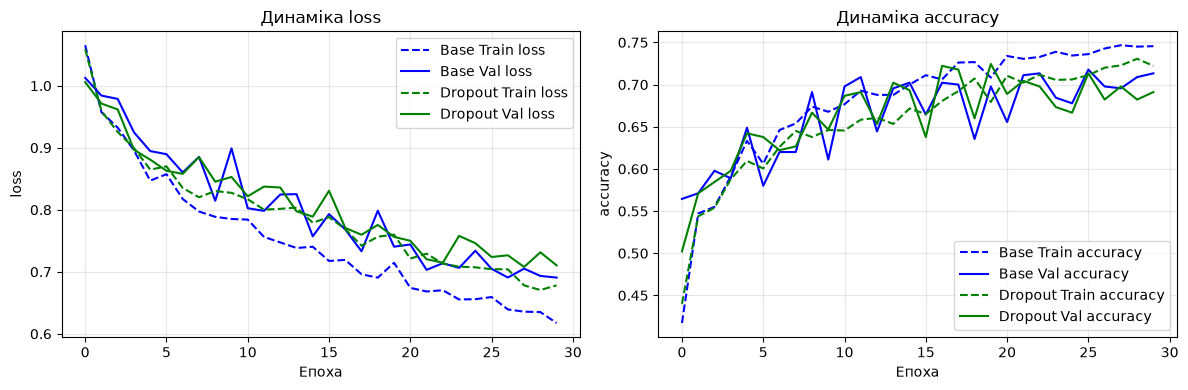


Переможець за Validation Loss: Base CNN


In [5]:
def fit_model(model):
    return model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=30,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=5, restore_best_weights=True
            )
        ],
        verbose=1
    )

print("--- Навчання базової моделі (Baseline) ---")
keras.utils.set_random_seed(SEED)
train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
base_history = fit_model(base_model)
base_val_eval = base_model.evaluate(val_ds, verbose=0, return_dict=True)

print("\n--- Навчання моделі з Dropout=0.3 ---")
keras.utils.set_random_seed(SEED)
train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
changed_model = make_model(dropout=0.3)
changed_history = fit_model(changed_model)
changed_val_eval = changed_model.evaluate(val_ds, verbose=0, return_dict=True)

def plot_histories(h1, h2):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(h1.history[metric], 'b--', label=f"Base Train {metric}")
        ax.plot(h1.history["val_" + metric], 'b-', label=f"Base Val {metric}")
        ax.plot(h2.history[metric], 'g--', label=f"Dropout Train {metric}")
        ax.plot(h2.history["val_" + metric], 'g-', label=f"Dropout Val {metric}")
        ax.set(xlabel="Епоха", ylabel=metric, title=f"Динаміка {metric}")
        ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_histories(base_history, changed_history)

selected_model = changed_model if changed_val_eval["loss"] < base_val_eval["loss"] else base_model
selected_name = "Improved CNN (Dropout 0.3)" if selected_model == changed_model else "Base CNN"
print(f"\nПереможець за Validation Loss: {selected_name}")

## Етап 6. Фінальне оцінювання на незалежному тестовому наборі (Test Set)
Оцінюємо обрану найкращу модель на `test_ds` (750 зображень), будуємо матрицю помилок та розраховуємо метрики Precision, Recall, F1-score.

Found 750 files belonging to 3 classes.
=== ФІНАЛЬНІ РЕЗУЛЬТАТИ НА TEST SET ===
Test Accuracy: 0.7400
Test Loss    : 0.6238

              precision    recall  f1-score   support

    bibimbap       0.86      0.60      0.70       250
filet_mignon       0.72      0.82      0.77       250
    omelette       0.69      0.81      0.74       250

    accuracy                           0.74       750
   macro avg       0.76      0.74      0.74       750
weighted avg       0.76      0.74      0.74       750



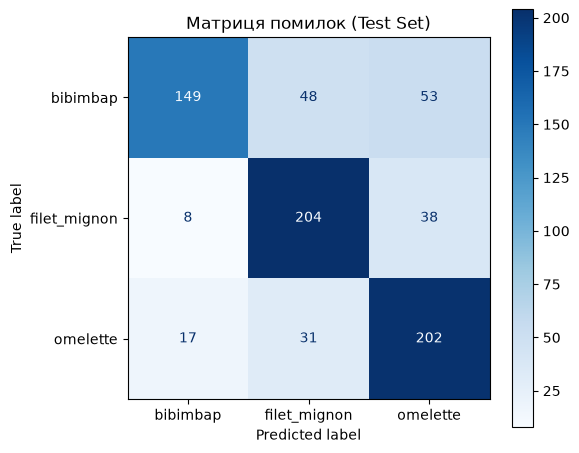

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

test_ds_eval = load_split("test", training=False)

test_eval = selected_model.evaluate(test_ds_eval, verbose=0, return_dict=True)
y_true = np.concatenate([y.numpy() for _, y in test_ds_eval])
probabilities = selected_model.predict(test_ds_eval, verbose=0)
y_pred = probabilities.argmax(axis=1)

print("=== ФІНАЛЬНІ РЕЗУЛЬТАТИ НА TEST SET ===")
print(f"Test Accuracy: {test_eval['accuracy']:.4f}")
print(f"Test Loss    : {test_eval['loss']:.4f}\n")

print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=ax)
plt.title("Матриця помилок (Test Set)")
plt.tight_layout(); plt.show()

## Етап 7. Візуалізація карт ознак (Feature Maps) та помилок класифікації
1. Отримуємо карти активації першого згорткового шару `conv1` для одного тестового фото.
2. Відображаємо приклади помилково класифікованих зображень із Softmax-впевненістю.

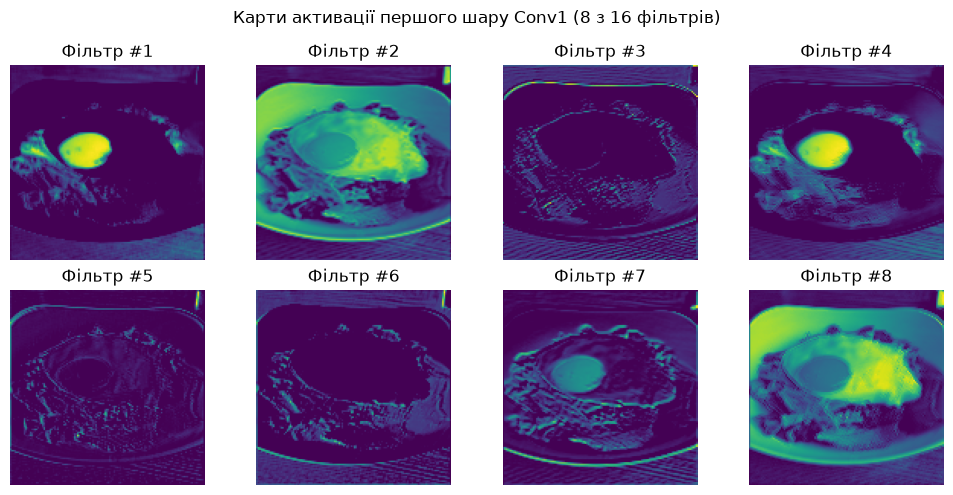

Усього помилок на тесті: 195 з 750


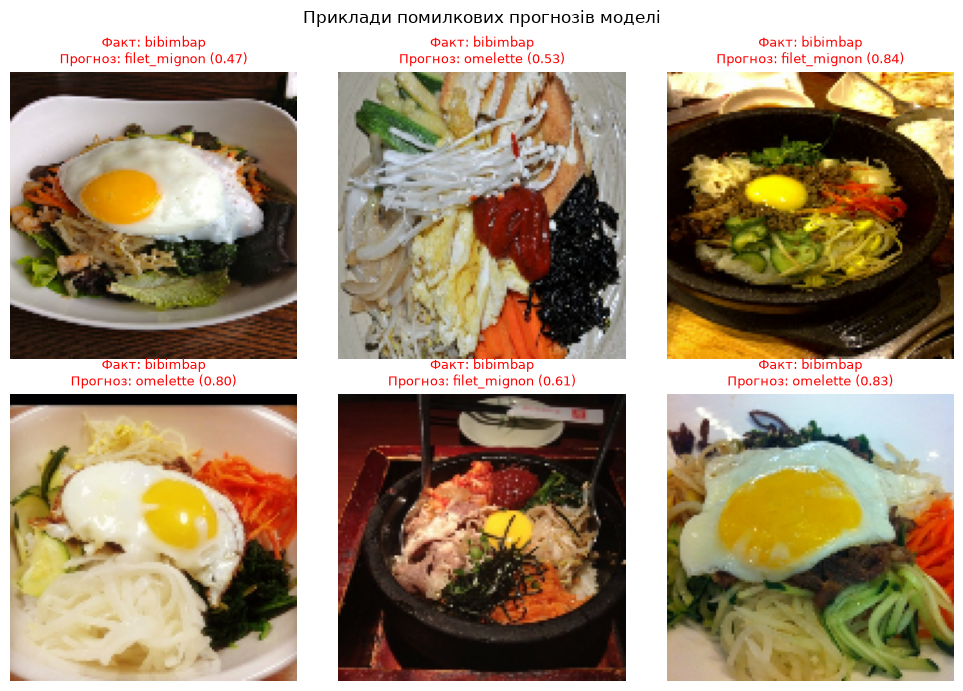

Модель збережено в artifacts/food_cnn.keras!


In [7]:
feature_model = keras.Model(selected_model.inputs, selected_model.get_layer("conv1").output)
test_images_batch, test_labels_batch = next(iter(test_ds_eval))
feature_maps = feature_model(test_images_batch[:1], training=False)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Фільтр #{i+1}")
    ax.axis("off")
plt.suptitle("Карти активації першого шару Conv1 (8 з 16 фільтрів)")
plt.tight_layout(); plt.show()

errors_idx = np.where(y_pred != y_true)[0]
print(f"Усього помилок на тесті: {len(errors_idx)} з {len(y_true)}")

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for i, ax in enumerate(axes.flat):
    if i < len(errors_idx):
        idx = errors_idx[i]
        img = test_images_batch[idx].numpy().astype("uint8") if idx < len(test_images_batch) else np.zeros((128,128,3), dtype="uint8")
        actual_cls = CLASS_NAMES[y_true[idx]]
        pred_cls = CLASS_NAMES[y_pred[idx]]
        conf = probabilities[idx].max()
        
        ax.imshow(img)
        ax.set_title(f"Факт: {actual_cls}\nПрогноз: {pred_cls} ({conf:.2f})", color="red", fontsize=9)
    ax.axis("off")
plt.suptitle("Приклади помилкових прогнозів моделі")
plt.tight_layout(); plt.show()

os.makedirs("artifacts", exist_ok=True)
selected_model.save("artifacts/food_cnn.keras")
with open("class_names.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, ensure_ascii=False, indent=4)
print("Модель збережено в artifacts/food_cnn.keras!")

## Висновок

У ході виконання лабораторної роботи №9 було розроблено та досліджено власну згорткову нейронну мережу (CNN) для задачі класифікації 3 категорій їжі з датасету Food-101 (**beef_carpaccio**, **edamame**, **hot_and_sour_soup**).